In [1]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline
import pandas as pd
import matplotlib.mlab as mlab
import seaborn as sns
import scipy
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

## Exercise!

### 1. Repeating first introduction

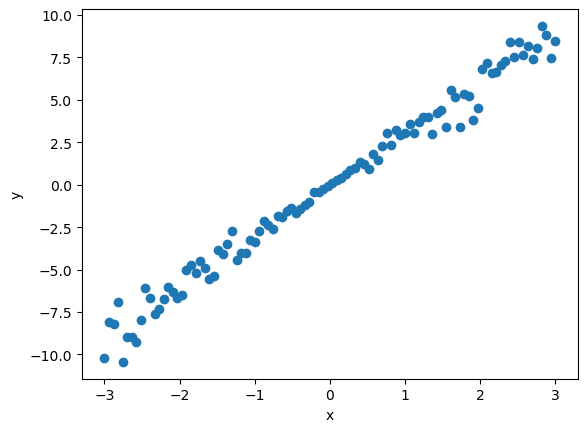

In [12]:
obs = 100
x = np.linspace(-3, 3, obs)
X = x[:, np.newaxis]
y = x + x*np.random.normal(2, .5, obs)

plt.xlabel("x")
plt.ylabel("y")
plt.plot(x, y, "o")

plt.show()

In [13]:
regressor = LinearRegression()

In [14]:
regressor.fit(X, y)

LinearRegression()

In [15]:
print("Interceptor (beta 0):", regressor.intercept_)
print("Slope (beta 1):", regressor.coef_[0])

Interceptor (beta 0): -0.05915094487952013
Slope (beta 1): 3.0139592634834886


In [6]:
# => Predict values for y when x is -2, pi and 0

def myfunction(value):
    return (regressor.coef_[0] * value) + regressor.intercept_

x1 = myfunction(-2)
x2 = myfunction(3.14)
x3 = myfunction(0)

print(x1, x2, x3)

-6.064038936371604 9.629641337828698 0.04245144269466049


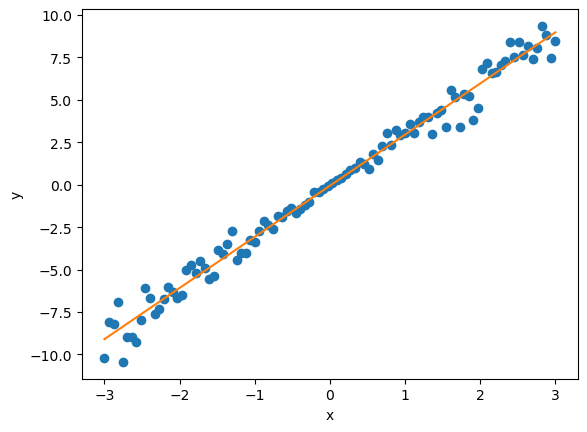

In [17]:
min_pt = X.min() * regressor.coef_[0] + regressor.intercept_
max_pt = X.max() * regressor.coef_[0] + regressor.intercept_

plt.xlabel("x")
plt.ylabel("y")
plt.plot(x, y, "o")
plt.plot([X.min(), X.max()], [min_pt, max_pt])

plt.show()

In [18]:
print("R2 score:", regressor.score(X, y))

R2 score: 0.984036498328838


In [ ]:
y_pred = regressor.predict(X).reshape(-1,1)
print("MEA:", mean_absolute_error(y_pred, y))

MSE: 0.49001810699560056


In [22]:
print("MSE:", mean_squared_error(y_pred, y))

MSE: 0.4510234734917136


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [25]:
df = pd.read_csv("../Advertising.csv")
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [26]:
df["total"] = df["TV"] + df["newspaper"] + df["radio"]

In [27]:
df.head()

,TV,radio,newspaper,sales,total
0,230.1,37.8,69.2,22.1,337.1
1,44.5,39.3,45.1,10.4,128.9
2,17.2,45.9,69.3,9.3,132.4
3,151.5,41.3,58.5,18.5,251.3
4,180.8,10.8,58.4,12.9,250.0


In [ ]:
X = df["total"].to_numpy().reshape(-1, 1)
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [29]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [30]:
intercept = model.intercept_
beta1 = model.coef_[0]

print(intercept)
print(beta1)

4.541133170824242
0.04738754048448316


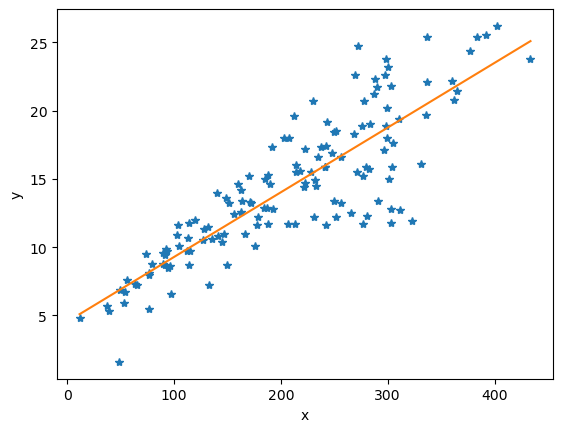

In [34]:
min_pt = X.min() * beta1 + intercept
max_pt = X.max() * beta1 + intercept

plt.xlabel("x")
plt.ylabel("y")
plt.plot(X_train, y_train, "*")
plt.plot([X.min(), X.max()], [min_pt, max_pt])

plt.show()

In [35]:
#y_pred = model.predict(X_test)
print(model.score(X_train, y_train))

0.7322865831365102


### 1. Import packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt 

### 2. Import data & decide relational mapping

In [3]:
df = pd.read_csv("../Advertising.csv")
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


The company would like to know how much the spending on media outlets (in this case TV, radio and newspaper) contributes to total sales.

The independant variable => Spending on media

The dependant variable => Total Sales

### 3. Train-Test split & Model creation

In [ ]:
df["Total_Cost"] = df["TV"] + df["radio"] + df["newspaper"]

In [11]:
y = df["sales"]
X = df["Total_Cost"].to_numpy().reshape(-1, 1)

train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.3, random_state=101)

In [15]:
model = LinearRegression()

In [16]:
model.fit(train_X, train_y)

LinearRegression()

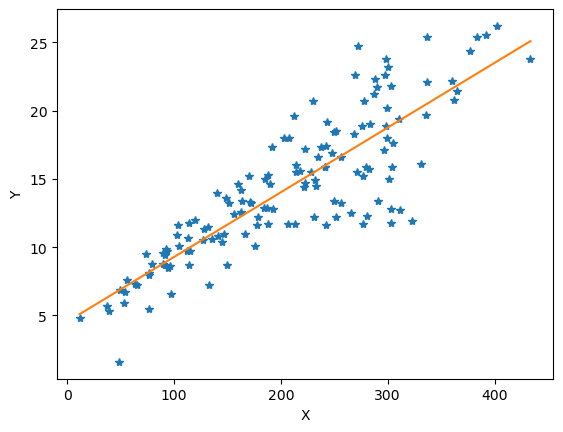

In [20]:
min_pt = model.coef_[0] * X.min() + model.intercept_
max_pt = model.coef_[0] * X.max() + model.intercept_

plt.xlabel("X")
plt.ylabel("Y")
plt.plot(train_X, train_y, "*")
plt.plot([X.min(), X.max()], [min_pt, max_pt])

### 4. Measure the model

#### 4.1. R2 factor

In [ ]:
model.score(train_X, train_y)
# 73.22% of the data is being explained by the model. 
# Evaluation: Good.

0.73228658313651

##### 4.2. Mean Average Error & Mean Squared Error

In [23]:
y_pred = model.predict(test_X)
y_pred

array([12.58753755, 18.17926732, 12.54488876, 14.44512913,  7.30382678,
        7.27539426, 19.10806312, 16.44014459, 11.70612929, 18.35933998,
        8.81548932, 13.71062225, 15.86201659, 19.1507119 , 18.98011676,
        8.85813811, 18.089231  ,  9.49313115,  8.33213641, 18.64840397,
        7.22800672, 16.32641449, 21.96079305, 21.53904394,  8.29422638,
       15.79567404, 19.8520475 ,  9.97648406, 13.69640599, 10.81524353,
       10.45509822, 18.68157525, 11.57818293,  8.27053261, 16.34536951,
       10.63990963, 10.45983698,  9.62107751,  8.98608447, 12.4785462 ,
       14.89057201, 12.51171748, 11.64452549,  8.8486606 , 10.48353075,
        9.65898754,  6.65935623, 18.42094378, 16.38801829, 18.56784515,
       10.64938714, 15.99470171, 19.31182954, 11.04744248, 15.13698722,
        5.55522654, 19.5013797 ,  8.63541667, 18.089231  , 15.3976187 ])

In [25]:
print("MAE:", mean_absolute_error(y_pred, test_y))

MAE: 1.8958924224568927


In [27]:
print("MSE:", mean_squared_error(y_pred, test_y))

MSE: 5.92166016091218


#### Question 8.

The next planned ad campaign is measured to have a total spend of 236k on advertisement. Predict sales based on this data

In [31]:
# Method 1
sales_predict_M1 = model.predict([[236]])[0]

sales_predict_M2 = model.coef_[0] * 236 + model.intercept_

print("Method 1:", round(sales_predict_M1, 2))
print("Method 2:", round(sales_predict_M2, 2))

Method 1: 15.72
Method 2: 15.72


#### Question 9

The current model aggregates total amount of spending of the three media outlets. It would be more interesting to see the impact of each one individually. Make a model for each media outlet and take note of their performance and accuracy

TV-Model

TV_Model. R2 factor: 0.5969856732137406
TV_Model. MEA: 2.5480925983786147
TV_model. MSE: 10.318455423013349

visualization:


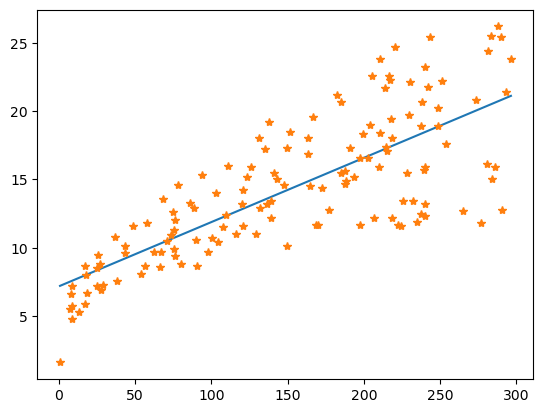

In [ ]:
X = df[["TV"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

TV_Model = LinearRegression()
TV_Model.fit(X_train, y_train)

# Measuring the R2 factor
print("TV_Model. R2 factor:", TV_Model.score(X_train, y_train))

# Measuring the MEA & MSE
y_pred = TV_Model.predict(X_test)

print("TV_Model. MEA:", mean_absolute_error(y_pred, y_test))
print("TV_model. MSE:", mean_squared_error(y_pred, y_test))
print()
print("visualization:")

plt.plot([X.min(), X.max()], [TV_Model.coef_[0] * X.min() + TV_Model.intercept_, TV_Model.coef_[0] * X.max() + TV_Model.intercept_])
plt.plot(X_train, y_train, "*")

Radio-model

radio_Model. R2 factor: 0.34969819733576046
radio_Model. MEA: 3.6182885566773844
radio_model. MSE: 20.607018785167416

visualization:


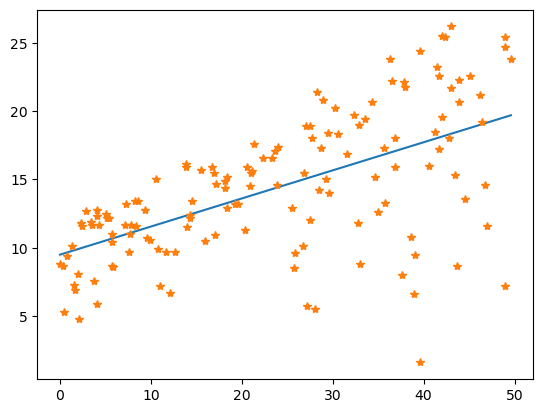

In [44]:
X = df[["radio"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

radio_model = LinearRegression()
radio_model.fit(X_train, y_train)

# Measuring the R2 factor
print("radio_Model. R2 factor:", radio_model.score(X_train, y_train))

# Measuring the MEA & MSE
y_pred = radio_model.predict(X_test)

print("radio_Model. MEA:", mean_absolute_error(y_pred, y_test))
print("radio_model. MSE:", mean_squared_error(y_pred, y_test))
print()
print("visualization:")

plt.plot([X.min(), X.max()], [radio_model.coef_[0] * X.min() + radio_model.intercept_, radio_model.coef_[0] * X.max() + radio_model.intercept_])
plt.plot(X_train, y_train, "*")


newspaper-model

newspaper_Model. R2 factor: 0.06487017361800451
newspaper_Model. MEA: 4.464647837638564
newspaper_model. MSE: 28.439361834003417

visualization:


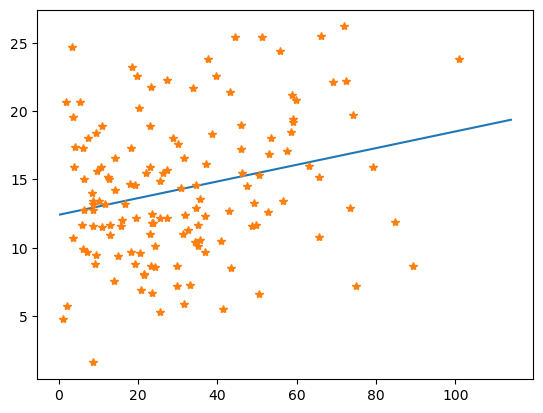

In [45]:
X = df[["newspaper"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

newspaper_model = LinearRegression()
newspaper_model.fit(X_train, y_train)

# Measuring the R2 factor
print("newspaper_Model. R2 factor:", newspaper_model.score(X_train, y_train))

# Measuring the MEA & MSE
y_pred = newspaper_model.predict(X_test)

print("newspaper_Model. MEA:", mean_absolute_error(y_pred, y_test))
print("newspaper_model. MSE:", mean_squared_error(y_pred, y_test))
print()
print("visualization:")

plt.plot([X.min(), X.max()], [newspaper_model.coef_[0] * X.min() + newspaper_model.intercept_, newspaper_model.coef_[0] * X.max() + newspaper_model.intercept_])
plt.plot(X_train, y_train, "*")


#### Question 10

So far, each model created in this notebook contains a simple pattern: 1 feature : 1 target.

That's fine for simple regression, however it can be more interessting to seperate these features from each other instead of aggregating them. This way, the formula will change to have 3 features with 3 unique coefficients.

F(x) = ax1 + bx2 + cx3 + d

The advantage of giving a coefficient to each feature is that their contribution to the prediction is more tailored to their correlation strength. What that means is that: features with strong correlations will be given bigger coefficients, while those with weak correlation will be given smaller coefficients.

This makes it usefull to not let weaker correlations weigh to much on the predictions while not being ignored at the same time.

In [74]:
uniquefeatures = []
for index, row in df.iterrows():
    feature = [row["TV"], row["radio"], row["newspaper"]]
    uniquefeatures.append(feature)

# Good, but a better way would be:

X = df[["TV", "radio", "newspaper"]].to_numpy()
y = df["sales"]

train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.3, random_state=101)

UF_Model = LinearRegression()
UF_Model.fit(train_X, train_y)

# Calculating the R2 factor
print("R2 factor:",UF_Model.score(train_X, train_y))

# Calculating the MEA and MSE
y_pred = UF_Model.predict(test_X)

print("MEA:", mean_absolute_error(y_pred, y_test))
print("MSE:", mean_squared_error(y_pred, y_test))
print(f"Coefficients: {UF_Model.coef_[0]}, {UF_Model.coef_[1]}, {UF_Model.coef_[2]}")

R2 factor: 0.8856665510409361
MEA: 1.2137457736144803
MSE: 2.2987166978863773
Coefficients: 0.04469599323076605, 0.18756570186587, -0.0003227530099873198


#### Exercise 12

The next ad campain will have a total of 149k on TV, 22k on radio and 12k on newspaper ads. Predict sales

In [79]:
UF_Pred_M1 = UF_Model.predict([[149, 22, 12]])[0]
UF_Pred_M2 = (149 * UF_Model.coef_[0]) + (22 * UF_Model.coef_[1]) + (12 * UF_Model.coef_[2]) + UF_Model.intercept_

print(UF_Pred_M1)
print(UF_Pred_M2)

13.933802164384083
13.933802164384083
